# Standalone global H1–H12 price XGBoost training

This Colab notebook needs only `price_horizon_training_dataset.csv`. It creates chronological splits, preprocesses the price features, trains XGBoost, evaluates validation and test periods, displays diagnostic graphs, and saves the complete fitted pipeline.

In [24]:
%pip install -q pandas scikit-learn xgboost joblib matplotlib seaborn

## Mount Google Drive and configure paths

Upload the training CSV to `MyDrive/demand-forecasting/Dataset/price_horizon_training_dataset.csv`. Model artifacts are first saved in Colab and then copied to `MyDrive/demand-forecasting/artifacts/price`.

In [25]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
import xgboost
from google.colab import drive

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_DATA_FILE = DRIVE_PROJECT_DIR / "Dataset" / "price_horizon_training_dataset.csv"
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / "artifacts" / "price"
LOCAL_ARTIFACT_DIR = Path("/content/price_xgboost_artifacts")

if not DRIVE_DATA_FILE.exists():
    raise FileNotFoundError(
        f"Upload price_horizon_training_dataset.csv to: {DRIVE_DATA_FILE}"
    )

print(f"Dataset: {DRIVE_DATA_FILE}")
print(f"Local output: {LOCAL_ARTIFACT_DIR}")
print(f"Drive output: {DRIVE_ARTIFACT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: /content/drive/MyDrive/demand-forecasting/Dataset/price_horizon_training_dataset.csv
Local output: /content/price_xgboost_artifacts
Drive output: /content/drive/MyDrive/demand-forecasting/artifacts/price


## Load data and create chronological splits

The final three target months are reserved for testing, the preceding three target months are validation, and all earlier target months are training. Splitting by `target_month` keeps every row for the same future month in one split.

In [26]:
TARGET_COLUMN = "future_weighted_avg_procurement_price_rm_per_kg"
CATEGORICAL_FEATURES = ["crop", "location", "origin_season", "target_season"]
EXCLUDED_FEATURES = ["forecast_origin_month", "target_month", TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3

data = pd.read_csv(
    DRIVE_DATA_FILE,
    parse_dates=["forecast_origin_month", "target_month"],
)

required = [
    "forecast_origin_month", "target_month", "forecast_horizon",
    *CATEGORICAL_FEATURES, TARGET_COLUMN,
]
missing = [column for column in required if column not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if data[TARGET_COLUMN].isna().any():
    raise ValueError("Training data contains missing future price targets.")
if data.duplicated(["forecast_origin_month", "crop", "location", "forecast_horizon"]).any():
    raise ValueError("Training data contains duplicate horizon samples.")

data = data.sort_values(["target_month", "forecast_origin_month", "crop", "location"]).reset_index(drop=True)
final_month = data["target_month"].max().to_period("M").to_timestamp()
test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)

train = data[data["target_month"] < validation_start].copy()
validation = data[data["target_month"].between(validation_start, test_start - pd.DateOffset(months=1))].copy()
test = data[data["target_month"] >= test_start].copy()

for name, split in {"train": train, "validation": validation, "test": test}.items():
    if split.empty:
        raise ValueError(f"{name} split is empty.")
    if set(split["forecast_horizon"].unique()) != set(range(1, 13)):
        raise ValueError(f"{name} split does not contain every H1–H12 horizon.")

if not (train["target_month"].max() < validation["target_month"].min() < test["target_month"].min()):
    raise ValueError("Chronological split boundaries overlap.")

print(f"Train: {len(train):,} rows, {train.target_month.min().date()} to {train.target_month.max().date()}")
print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Train: 19,170 rows, 2022-02-01 to 2025-06-01
Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Define preprocessing and XGBoost

Categorical values are imputed and one-hot encoded. Numeric missing values use medians learned only from the data used to fit each pipeline.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor

FEATURE_COLUMNS = [column for column in data.columns if column not in EXCLUDED_FEATURES]
NUMERIC_FEATURES = [column for column in FEATURE_COLUMNS if column not in CATEGORICAL_FEATURES]
unexpected_text = [
    column for column in NUMERIC_FEATURES
    if not pd.api.types.is_numeric_dtype(data[column])
]
if unexpected_text:
    raise ValueError(f"Features need an explicit encoding policy: {unexpected_text}")

def build_pipeline(device="cpu"):
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    preprocessor = ColumnTransformer(
        [
            ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
            ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1,
        device=device,
    )
    return Pipeline([("preprocessor", preprocessor), ("model", model)])

def split_xy(frame):
    return frame[FEATURE_COLUMNS].copy(), frame[TARGET_COLUMN].copy()

print(f"Features: {len(FEATURE_COLUMNS)} ({len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric)")

Features: 56 (4 categorical, 52 numeric)


## Train, validate, refit, and test

Use `DEVICE = "cpu"` normally. Change it to `"cuda"` only when a Colab GPU runtime is enabled. The validation pipeline uses training rows only. A fresh final pipeline is then fitted on training plus validation rows before the untouched test evaluation.

In [28]:
DEVICE = "cpu"

X_train, y_train = split_xy(train)
X_validation, y_validation = split_xy(validation)
X_test, y_test = split_xy(test)

validation_pipeline = build_pipeline(DEVICE)
validation_pipeline.fit(X_train, y_train)
validation_values = validation_pipeline.predict(X_validation)

train_validation = pd.concat([train, validation], ignore_index=True).sort_values("target_month")
X_train_validation, y_train_validation = split_xy(train_validation)
final_pipeline = build_pipeline(DEVICE)
final_pipeline.fit(X_train_validation, y_train_validation)
test_values = final_pipeline.predict(X_test)

print("Training complete.")

Training complete.


## Evaluate overall and by horizon

In [29]:
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

KEY_COLUMNS = [
    "forecast_origin_month", "target_month", "crop", "location",
    "forecast_horizon", TARGET_COLUMN,
]

def prediction_table(frame, values, split_name):
    output = frame[KEY_COLUMNS].copy()
    output["xgboost_prediction"] = values
    output["split"] = split_name
    output["absolute_error"] = (output[TARGET_COLUMN] - output["xgboost_prediction"]).abs()
    return output

def metric_values(frame):
    actual = frame[TARGET_COLUMN].to_numpy(dtype=float)
    predicted = frame["xgboost_prediction"].to_numpy(dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "mae": mean_absolute_error(actual, predicted),
        "rmse": np.sqrt(mean_squared_error(actual, predicted)),
        "wape": np.abs(actual - predicted).sum() / denominator if denominator > 0 else np.nan,
        "r2": r2_score(actual, predicted),
    }

validation_predictions = prediction_table(validation, validation_values, "validation")
test_predictions = prediction_table(test, test_values, "test")
records = []
for split_name, predictions in [("validation", validation_predictions), ("test", test_predictions)]:
    records.append({"model": "xgboost", "split": split_name, "forecast_horizon": "overall", "rows": len(predictions), **metric_values(predictions)})
    for horizon, group in predictions.groupby("forecast_horizon"):
        records.append({"model": "xgboost", "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **metric_values(group)})

metrics = pd.DataFrame(records)
display(metrics)

,model,split,forecast_horizon,rows,mae,rmse,wape,r2
0,xgboost,validation,overall,1620,0.125950,0.162345,0.029519,0.990794
1,xgboost,validation,1,135,0.118793,0.155204,0.027842,0.991586
2,xgboost,validation,2,135,0.125596,0.163339,0.029436,0.990680
3,xgboost,validation,3,135,0.122609,0.162452,0.028737,0.990781
4,xgboost,validation,4,135,0.122104,0.158508,0.028618,0.991224
5,xgboost,validation,5,135,0.116719,0.151465,0.027356,0.991986
6,xgboost,validation,6,135,0.115095,0.147849,0.026975,0.992364
7,xgboost,validation,7,135,0.123285,0.156976,0.028895,0.991392
8,xgboost,validation,8,135,0.128703,0.163078,0.030165,0.990710
9,xgboost,validation,9,135,0.132903,0.168048,0.031149,0.990135


## Visualize model results

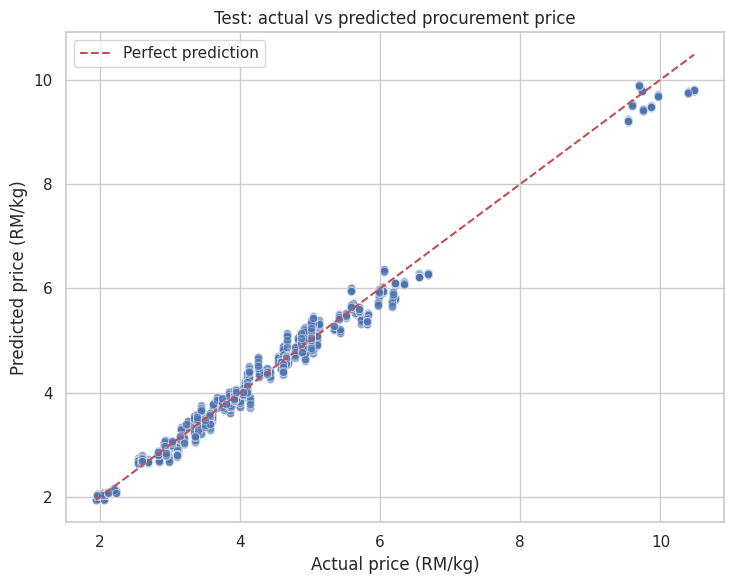

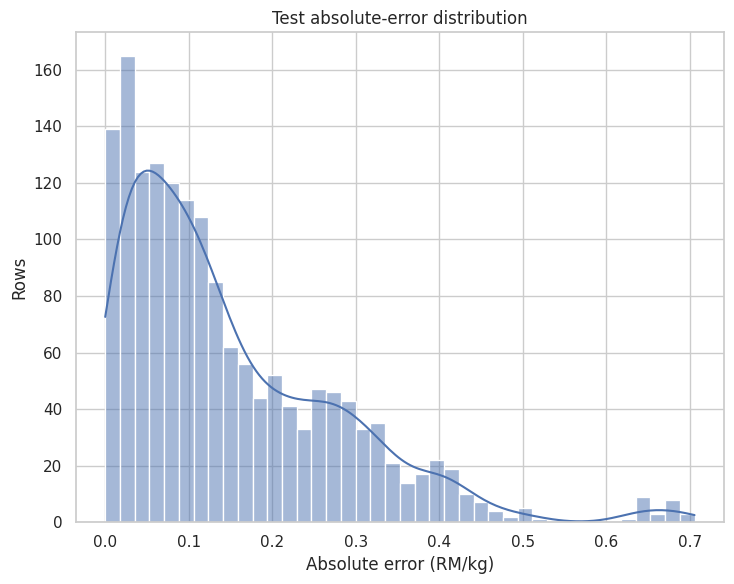

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Scatter plot: actual vs predicted
fig1, ax1 = plt.subplots(figsize=(7.5, 6))
sns.scatterplot(
    data=test_predictions,
    x=TARGET_COLUMN,
    y="xgboost_prediction",
    alpha=0.55,
    ax=ax1,
)
minimum = min(test_predictions[TARGET_COLUMN].min(), test_predictions["xgboost_prediction"].min())
maximum = max(test_predictions[TARGET_COLUMN].max(), test_predictions["xgboost_prediction"].max())
ax1.plot([minimum, maximum], [minimum, maximum], "r--", label="Perfect prediction")
ax1.set_title("Test: actual vs predicted procurement price")
ax1.set_xlabel("Actual price (RM/kg)")
ax1.set_ylabel("Predicted price (RM/kg)")
ax1.legend()
plt.tight_layout()
plt.show()

# Histogram: absolute-error distribution
fig2, ax2 = plt.subplots(figsize=(7.5, 6))
sns.histplot(test_predictions["absolute_error"], bins=40, kde=True, ax=ax2)
ax2.set_title("Test absolute-error distribution")
ax2.set_xlabel("Absolute error (RM/kg)")
ax2.set_ylabel("Rows")
plt.tight_layout()
plt.show()


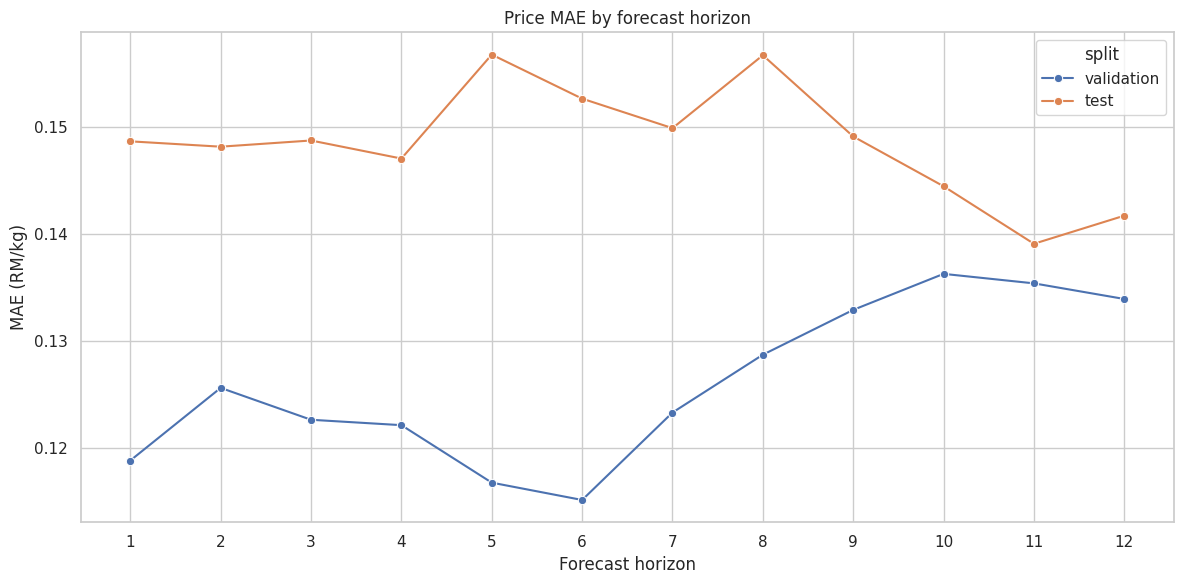

In [31]:
metrics_by_horizon = metrics[metrics["forecast_horizon"] != "overall"].copy()
metrics_by_horizon["forecast_horizon"] = metrics_by_horizon["forecast_horizon"].astype(int)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=metrics_by_horizon,
    x="forecast_horizon",
    y="mae",
    hue="split",
    marker="o",
)
plt.title("Price MAE by forecast horizon")
plt.xlabel("Forecast horizon")
plt.ylabel("MAE (RM/kg)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## Save locally and copy to Google Drive

The `.joblib` file contains both preprocessing and XGBoost. Always use this complete pipeline for prediction. The native `.json` contains only the XGBoost regressor and is saved for portability and inspection.

In [32]:
local_model_dir = LOCAL_ARTIFACT_DIR / "models"
local_prediction_dir = LOCAL_ARTIFACT_DIR / "predictions"
local_report_dir = LOCAL_ARTIFACT_DIR / "reports"
for directory in [local_model_dir, local_prediction_dir, local_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

pipeline_file = local_model_dir / "global_xgboost_pipeline.joblib"
native_file = local_model_dir / "global_xgboost_model.json"
validation_file = local_prediction_dir / "xgboost_validation_predictions.csv"
test_file = local_prediction_dir / "xgboost_test_predictions.csv"
metrics_file = local_report_dir / "xgboost_metrics.csv"
metadata_file = local_report_dir / "xgboost_training_metadata.json"

joblib.dump(final_pipeline, pipeline_file)
final_pipeline.named_steps["model"].save_model(native_file)
validation_predictions.to_csv(validation_file, index=False)
test_predictions.to_csv(test_file, index=False)
metrics.to_csv(metrics_file, index=False)

metadata = {
    "model": "global_direct_multi_horizon_price_xgboost",
    "target": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS,
    "categorical_features": CATEGORICAL_FEATURES,
    "validation_months": VALIDATION_MONTHS,
    "test_months": TEST_MONTHS,
    "final_fit_data": "train + validation",
    "validation_prediction_model": "train only",
    "test_prediction_model": "train + validation",
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "joblib": joblib.__version__,
    },
}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

local_files = [pipeline_file, native_file, validation_file, test_file, metrics_file, metadata_file]
for source in local_files:
    relative = source.relative_to(LOCAL_ARTIFACT_DIR)
    destination = DRIVE_ARTIFACT_DIR / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

print("Saved locally:")
for path in local_files:
    print(path)
print(f"\nCopied to Google Drive: {DRIVE_ARTIFACT_DIR}")

Saved locally:
/content/price_xgboost_artifacts/models/global_xgboost_pipeline.joblib
/content/price_xgboost_artifacts/models/global_xgboost_model.json
/content/price_xgboost_artifacts/predictions/xgboost_validation_predictions.csv
/content/price_xgboost_artifacts/predictions/xgboost_test_predictions.csv
/content/price_xgboost_artifacts/reports/xgboost_metrics.csv
/content/price_xgboost_artifacts/reports/xgboost_training_metadata.json

Copied to Google Drive: /content/drive/MyDrive/demand-forecasting/artifacts/price
